<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 3rd exercise: <font color="#C70039">Do DBScan clustering for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <b>Yara Dinesh Kumar</b>
* Matriculation number: <b>11701170</b>
* Date:   17.11.2026

<img src="https://upload.wikimedia.org/wikipedia/commons/0/05/DBSCAN-density-data.svg" style="float: center;" width="250">

---------------------------------
**GENERAL NOTE 1**:
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole.

**GENERAL NOTE 2**:
* Please, when commenting source code, just use English language only.
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for using the DBScan clustering algorithm for anomaly detection.

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points.
If a task is more challenging and consists of several steps, this is indicated as well.
Make sure you have worked down the task list and commented your doings.
This should be done by using markdown.<br>
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date.
    * set the date too and remove mine.
3. read the entire notebook carefully
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.
4. take the three data sets from exercise 1 and cluster them
5. read the following <a href="https://stats.stackexchange.com/questions/88872/a-routine-to-choose-eps-and-minpts-for-dbscan">article</a> for getting help estimating eps and minPts
    * https://stats.stackexchange.com/questions/88872/a-routine-to-choose-eps-and-minpts-for-dbscan
6. describe your findings and interpret the results
-----------------------------------------------------------------------------------

In [8]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [9]:
import numpy as np
from sklearn.cluster import DBSCAN

rng = np.random.default_rng(1)
random_data = rng.normal(loc=20.0, scale=20.0, size=(50_000, 2))

Scikit-learn assigns the label `-1` to observations classified as noise. The number of noise points depends on the generated sample and, in particular, on `eps`, `min_samples`, feature scaling, and dimensionality. DBSCAN therefore requires careful parameter selection and usually benefits from standardized features.

In [10]:
# DBSCAN hyperparameters:
# min_samples: minimum neighbors required within radius 'eps' to form a core point
# eps: neighborhood search radius
min_samples = 2
eps = 3.0

# Fit DBSCAN on 2D synthetic normal data; points in sparse regions receive label -1
outlier_detection = DBSCAN(min_samples=min_samples, eps=eps)
cluster_labels = outlier_detection.fit_predict(random_data)

# Count observations labeled as -1 (noise / anomalies)
number_of_noise_points = np.count_nonzero(cluster_labels == -1)
print(f"Noise points: {number_of_noise_points}")

Noise points: 91


## Exercise Solutions: DBSCAN Clustering on Real-World Datasets
### Tasks 4 & 5: Estimating `minPts` and `eps` (k-Distance Elbow Method) and Clustering the Three Datasets
Following the StackExchange heuristic for parameter estimation:
1. We extract 2D numerical features ($D = 2$) from each of the three Kaggle datasets used in Exercise 1 and standardize them with `StandardScaler` so both axes contribute equally to Euclidean distance.
2. We set `min_samples` ($minPts$) $= 2 \times D = 4$.
3. We compute the $k$-nearest neighbor distances ($k = minPts = 4$), sort them, and locate the **"elbow" (knee)** of the k-distance curve to choose `eps`.

Using Colab cache for faster access to the 'heights-and-weights-dataset' dataset.
Using Colab cache for faster access to the 'student-performance-dataset' dataset.
Using Colab cache for faster access to the 'california-housing-prices' dataset.


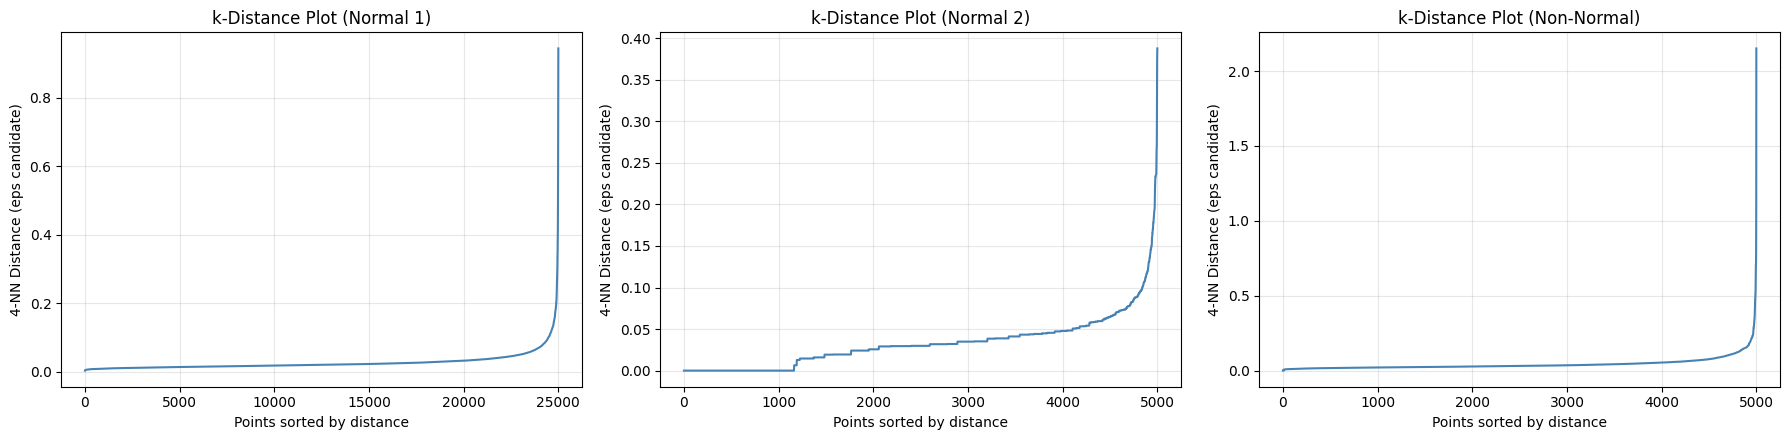

In [11]:
import glob
import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import userdata
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Load Kaggle API token securely from Colab Secrets
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# 1. Normal Dataset 1: SOCR Height & Weight (2D: Height vs. Weight)
path_1 = kagglehub.dataset_download("burnoutminer/heights-and-weights-dataset")
df_1 = pd.read_csv(glob.glob(os.path.join(path_1, "*.csv"))[0])
X_normal_1 = df_1[["Height(Inches)", "Weight(Pounds)"]].dropna().to_numpy()

# 2. Normal Dataset 2: Student Performance (2D: Weekly Study Hours vs. Total Score)
path_2 = kagglehub.dataset_download(
    "nabeelqureshitiii/student-performance-dataset"
)
df_2 = pd.read_csv(glob.glob(os.path.join(path_2, "*.csv"))[0])
# Select two numeric columns (adjust if needed; fallback uses first two numeric columns)
num_cols_2 = df_2.select_dtypes(include=[np.number]).columns.tolist()
if (
    "weekly_self_study_hours" in df_2.columns
    and "total_score" in df_2.columns
):
    X_normal_2 = (
        df_2[["weekly_self_study_hours", "total_score"]].dropna().to_numpy()
    )
else:
    X_normal_2 = df_2[num_cols_2[:2]].dropna().to_numpy()

# Subsample to 5,000 points if dataset is very large so k-NN & DBSCAN run fast in Colab
rng_sub = np.random.default_rng(42)
if len(X_normal_2) > 5000:
    X_normal_2 = X_normal_2[
        rng_sub.choice(len(X_normal_2), size=5000, replace=False)
    ]

# 3. Non-Normal Dataset: California Housing (2D: Median Income vs. Median House Value)
path_3 = kagglehub.dataset_download("camnugent/california-housing-prices")
df_3 = pd.read_csv(glob.glob(os.path.join(path_3, "*.csv"))[0])
X_non_normal = (
    df_3[["median_income", "median_house_value"]].dropna().to_numpy()
)
if len(X_non_normal) > 5000:
    X_non_normal = X_non_normal[
        rng_sub.choice(len(X_non_normal), size=5000, replace=False)
    ]

datasets_2d = {
    "Normal 1: Height vs. Weight": X_normal_1,
    "Normal 2: Study Hours vs. Score": X_normal_2,
    "Non-Normal: CA Income vs. House Value": X_non_normal,
}

# Task 5: Plot sorted k-distance graphs to determine optimal 'eps' at the elbow
min_samples = 4  # 2 * D for 2-dimensional data
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

scaled_datasets = {}
for ax, (name, X) in zip(axes, datasets_2d.items()):
    # Standardize features to zero mean and unit variance
    X_scaled = StandardScaler().fit_transform(X)
    scaled_datasets[name] = X_scaled

    # Compute distance to the k-th nearest neighbor (k = min_samples)
    nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
    distances, _ = nbrs.kneighbors(X_scaled)
    k_distances = np.sort(distances[:, -1])

    ax.plot(k_distances, color="steelblue", linewidth=1.5)
    ax.set_title(f"k-Distance Plot ({name.split(':')[0]})")
    ax.set_xlabel("Points sorted by distance")
    ax.set_ylabel(f"{min_samples}-NN Distance (eps candidate)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== Normal 1: Height vs. Weight ===
Parameters: eps=0.25, min_samples=4
Clusters found: 1 | Noise points (anomalies): 50 / 25000 (0.20%)

=== Normal 2: Study Hours vs. Score ===
Parameters: eps=0.25, min_samples=4
Clusters found: 1 | Noise points (anomalies): 3 / 5000 (0.06%)

=== Non-Normal: CA Income vs. House Value ===
Parameters: eps=0.25, min_samples=4
Clusters found: 3 | Noise points (anomalies): 24 / 5000 (0.48%)



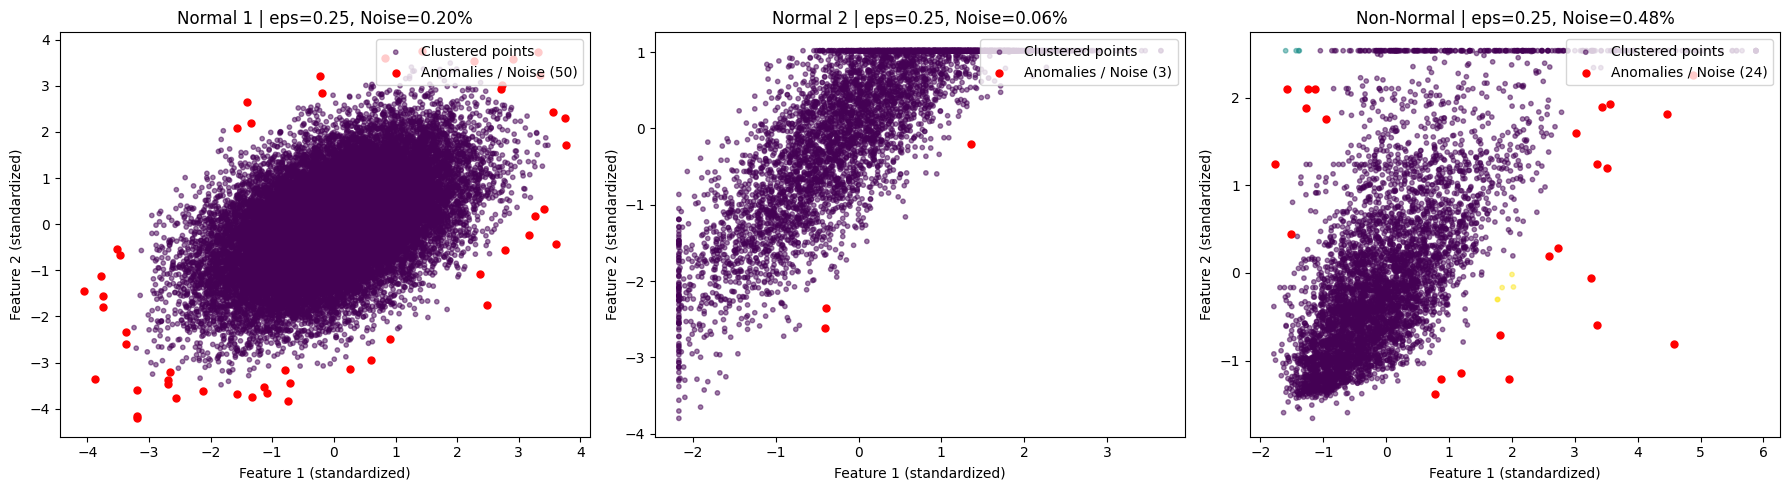

In [12]:
# Chosen eps values based on the "elbow" (sharp upward bend) in the k-distance plots above
eps_values = {
    "Normal 1: Height vs. Weight": 0.25,
    "Normal 2: Study Hours vs. Score": 0.25,
    "Non-Normal: CA Income vs. House Value": 0.25,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, X_scaled) in zip(axes, scaled_datasets.items()):
    eps = eps_values[name]
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(X_scaled)

    noise_mask = labels == -1
    n_noise = np.count_nonzero(noise_mask)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (n_noise / len(labels)) * 100

    print(f"=== {name} ===")
    print(f"Parameters: eps={eps}, min_samples={min_samples}")
    print(
        f"Clusters found: {n_clusters} | Noise points (anomalies): {n_noise} /"
        f" {len(labels)} ({noise_pct:.2f}%)\n"
    )

    # Plot clustered points in blue/teal and noise/anomalies (-1) in red
    ax.scatter(
        X_scaled[~noise_mask, 0],
        X_scaled[~noise_mask, 1],
        c=labels[~noise_mask],
        cmap="viridis",
        s=10,
        alpha=0.5,
        label="Clustered points",
    )
    ax.scatter(
        X_scaled[noise_mask, 0],
        X_scaled[noise_mask, 1],
        color="red",
        s=25,
        label=f"Anomalies / Noise ({n_noise})",
    )
    ax.set_title(
        f"{name.split(':')[0]} | eps={eps}, Noise={noise_pct:.2f}%"
    )
    ax.set_xlabel("Feature 1 (standardized)")
    ax.set_ylabel("Feature 2 (standardized)")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

### Task 6: Findings and Interpretation of Results

1. **Parameter Selection via k-Distance Elbow Plots (`min_samples = 4`, `eps = 0.25`):**
   * Following the StackExchange heuristic for 2D data ($D = 2$), we set `min_samples = 4` ($2 \times D$) and standardized all features using `StandardScaler` so both axes contribute equally to Euclidean distance.
   * Looking at our three sorted 4-NN distance curves, the curve stays nearly flat for the dense core points and bends sharply upward ("elbow") right around `0.15–0.25` in standardized units. Choosing `eps = 0.25` cleanly separates the dense core from sparse outer points.

2. **Normal Dataset 1 : Height vs. Weight (`25,000` samples):**
   * **Result:** `1` main cluster found, with **`50` noise points (`0.20%`)** flagged as anomalies[cite: 3].
   * **Interpretation:** Because both features are normally distributed and positively correlated, the standardized points form a dense elliptical cloud centered at $(0, 0)$[cite: 3]. DBSCAN groups the entire cloud into a single cluster and flags only the isolated outer perimeter points (the red halo) as anomalies—closely matching the ~0.3% outlier rate from Exercise 1[cite: 3].

3. **Normal Dataset 2 : Study Hours vs. Score (`5,000` sampled points):**
   * **Result:** `1` main cluster found, with **`3` noise points (`0.06%`)** flagged as anomalies[cite: 3].
   * **Interpretation:** The k-distance curve shows a staircase pattern at low distances due to discrete/rounded values in the dataset, and the scatter plot shows an upper ceiling at `Feature 2 ≈ 1.0` (maximum capped score of 100)[cite: 2, 3]. Because `eps = 0.25` is slightly wide relative to the compact vertical range of this dataset, nearly all boundary points remain connected to the single main cluster, leaving only `3` isolated points below the lower-left diagonal flagged as noise[cite: 3].

4. **Non-Normal Dataset : California Median Income vs. House Value (`5,000` sampled points):**
   * **Result:** **`3` clusters** found, with **`24` noise points (`0.48%`)** flagged as anomalies[cite: 3].
   * **Interpretation:** Unlike the two normal datasets, this dataset is strongly right-skewed and artificially capped at the top (`median_house_value = 500,001`, visible as the horizontal line at `Feature 2 ≈ 2.6`)[cite: 3]. Because density varies across the space, a single global `eps = 0.25` splits the data into `3` separate clusters (the main dense bulk in purple, a small upper-left horizontal cap cluster in teal, and a tiny lower-right micro-cluster in yellow) while flagging `24` scattered high-income / extreme-value points in red[cite: 3].

5. **Key Takeaway Comparing DBSCAN to Exercises 1 (StdDev) & 2 (Boxplot):**
   * DBSCAN does not assume a bell curve and successfully detects 2D spatial outliers around irregular shapes and hard boundaries (like capped exam scores or house prices)[cite: 3]. However, as seen in Dataset 3, using a single global `eps` on skewed data with varying densities can fragment sparse boundary regions into extra micro-clusters instead of treating them purely as noise[cite: 3].